# recursive-collapse-filter — Colab'da eğitim

Bu notebook deney hatlarını Colab GPU'sunda çalıştırır. **Tüm çıktılar Google Drive'a yazılır**, böylece
oturum kapansa bile kaybolmaz. Hücreleri yeniden çalıştırınca pipeline kaldığı nesilden devam eder.

Adım adım talimatlar: [COLAB.md](https://github.com/GuneyTunc/recursive-collapse-filter/blob/main/COLAB.md)

1. **Çalışma zamanı → Çalışma zamanı türünü değiştir → L4 GPU** (yoksa T4). TPU seçme.
2. Hücreleri sırayla çalıştır. Yalnızca **Ayarlar** hücresini düzenlemen gerekir.
3. Aynı tohum için hatları **sırayla** çalıştır: nesil-0 modeli tüm hatlarca paylaşılır.
   Aynı Drive klasörüne iki Colab oturumundan aynı anda yazma.

## 1. GPU kontrolü

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
import torch
print("torch", torch.__version__, "| CUDA:", torch.cuda.is_available())
assert torch.cuda.is_available(), "GPU yok: Çalışma zamanı → Çalışma zamanı türünü değiştir → GPU"
major, minor = torch.cuda.get_device_capability()
print("compute capability", f"{major}.{minor}", "→ precision:", "bf16" if major >= 8 else "fp16 (T4)")

# Sampling throughput grows with batch size; ~2.8 GB per 128 documents of 300 tokens was measured.
vram_gb = torch.cuda.get_device_properties(0).total_memory / 2**30
AUTO_GEN_BATCH = 1024 if vram_gb >= 40 else 512 if vram_gb >= 20 else 256 if vram_gb >= 14 else 128
print(f"VRAM {vram_gb:.1f} GB → generate.batch_size={AUTO_GEN_BATCH}")

name, memory.total [MiB]
NVIDIA L4, 23034 MiB
torch 2.14.1+cu130 | CUDA: True
compute capability 8.9 → precision: bf16
VRAM 22.0 GB → generate.batch_size=512


## 2. Ayarlar

In [8]:
REPO_URL = "https://github.com/GuneyTunc/recursive-collapse-filter.git"
BRANCH = "main"

DRIVE_ROOT = "/content/drive/MyDrive/recursive-collapse-filter"  # çıktılar, veri, rapor
LINES = ["dual_filter", "human_mix"]          # sırayla çalışır: raw, dual_filter, human_mix, density_only, ppl_only, semdedup, dual_human, accumulate
SEEDS = [0]              # bir oturumda 1 tohum önerilir (~4 saat / hat)
GEN_BATCH = "auto"       # üretim batch'i: "auto" = VRAM'e göre (T4 256, L4 512, A100/G4 1024); yalnızca hız ayarı
EXTRA = [                # isteğe bağlı config değişiklikleri: "anahtar=değer"
    # "data.n_train=5000",       # süreyi yarıya indirir (tüm hatlarda aynı kullan!)
]

## 3. Drive ve kod

In [3]:
from google.colab import drive
drive.mount("/content/drive")

import os, pathlib
REPO_DIR = "/content/recursive-collapse-filter"
if pathlib.Path(REPO_DIR).exists():
    !git -C {REPO_DIR} fetch -q origin && git -C {REPO_DIR} checkout -q {BRANCH} && git -C {REPO_DIR} pull -q --ff-only
else:
    !git clone -q -b {BRANCH} {REPO_URL} {REPO_DIR}
%cd {REPO_DIR}
!git log --oneline -1

os.environ["MC_OUTPUT_DIR"] = f"{DRIVE_ROOT}/outputs"
os.environ["PYTHONIOENCODING"] = "utf-8"
# Variable-length batches fragment the CUDA cache; on a T4 this caused an OOM retry during training.
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
DATA_DIR = f"{DRIVE_ROOT}/data/real"  # gerçek veri bir kez indirilir, sonraki oturumlar Drive'dan okur
pathlib.Path(DRIVE_ROOT).mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
/content/recursive-collapse-filter
bbdf1f2 (HEAD -> main, origin/main, origin/heuristic-tolerance-interim-report, origin/HEAD) Tune Colab notebook from the first T4 run and record its results


## 4. Kurulum ve testler
Colab'ın kendi PyTorch'u kullanılır; yalnızca eksik paketler kurulur (~1 dk).

In [4]:
!pip install -q -r requirements.txt
!python -m pytest -q tests

........................................                                 [100%]
40 passed in 3.92s


## 5. (İsteğe bağlı) Duman testi
Birkaç dakikada uçtan uca çalışır. Yeni bir GPU türünde ilk kez çalıştırıyorsan önerilir.
Çıktıları `/content` altına yazar, Drive'a değil.

In [ ]:
!MC_OUTPUT_DIR=/content/outputs_smoke python -m src.pipeline --config configs/smoke.yaml \
    --set selection.method=dual --set experiment.line=smoke_dual

## 6. Eğitim
Uzun sürer. Oturum koparsa 3. hücreden itibaren yeniden çalıştır: tamamlanan nesiller atlanır.
İlerleme Drive'da `outputs/<hat>/run.log` dosyasına da yazılır.

In [9]:
import shlex
gen_batch = AUTO_GEN_BATCH if GEN_BATCH == "auto" else GEN_BATCH
overrides = [f"data.data_dir={DATA_DIR}", f"generate.batch_size={gen_batch}", *EXTRA]  # EXTRA wins
sets = " ".join(f"--set {shlex.quote(s)}" for s in overrides)
seeds = " ".join(map(str, SEEDS))
for line in LINES:
    print(f"===== {line} | seeds {seeds} =====")
    !python -m src.pipeline --config configs/lines/{line}.yaml --seeds {seeds} {sets}

===== dual_filter | seeds 0 =====
09:35:15 INFO [dual_filter seed 0] gen 1 already done
09:35:15 INFO [dual_filter seed 0] gen 2 already done
09:35:15 INFO [dual_filter seed 0] gen 3 already done
09:35:15 INFO [dual_filter seed 0] gen 4 already done
09:35:15 INFO [dual_filter seed 0] gen 5 already done
===== human_mix | seeds 0 =====
09:35:17 INFO [human_mix seed 0] gen 1 already done
09:35:18 INFO [human_mix seed 0] gen 2 already done
09:35:18 INFO [human_mix seed 0] gen 3 already done
09:35:18 INFO [human_mix seed 0] gen 4 already done
09:35:18 INFO [human_mix seed 0] gen 5 already done


## 7. Rapor
Tüm hatların `metrics.json` dosyalarını toplar; tablo ve grafikler Drive'daki `results/` klasörüne yazılır.

Wrote 18 rows to /content/drive/MyDrive/recursive-collapse-filter/results


,line,generation,n_seeds,test_ppl_mean,rare_recall_mean,vendi_mean,distinct_2_mean,js_real_gen_mean,frechet_real_mean,rep3_mean_mean
0,dual_filter,0,1,5.1915,0.3014,26.9899,0.3322,0.0228,0.0445,0.0223
1,dual_filter,1,1,5.5009,0.2749,27.8388,0.3343,0.0245,0.0460,0.0235
2,dual_filter,2,1,5.6492,0.2570,27.2282,0.3267,0.0257,0.0449,0.0216
3,dual_filter,3,1,5.7595,0.2416,29.5309,0.3299,0.0279,0.0515,0.0216
4,dual_filter,4,1,5.8452,0.2164,28.5481,0.3309,0.0291,0.0523,0.0204
5,dual_filter,5,1,5.9234,0.2057,29.4631,0.3308,0.0308,0.0581,0.0201
6,human_mix,0,1,5.1915,0.3014,26.9899,0.3322,0.0228,0.0445,0.0223
7,human_mix,1,1,5.3942,0.2787,27.6506,0.3349,0.0246,0.0469,0.0214
8,human_mix,2,1,5.4574,0.2677,29.7725,0.3437,0.0262,0.0512,0.0210
9,human_mix,3,1,5.4898,0.2686,29.5562,0.3420,0.0263,0.0497,0.0200


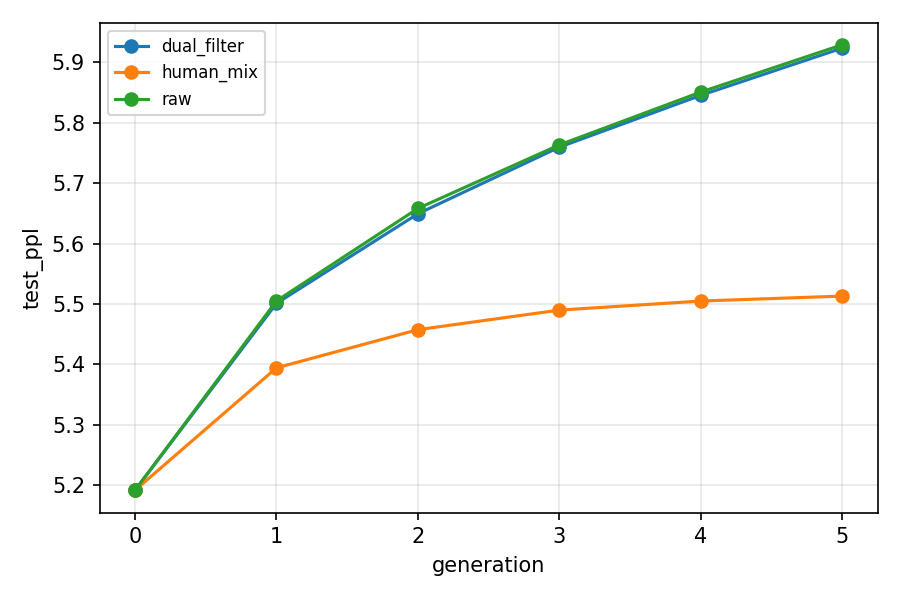

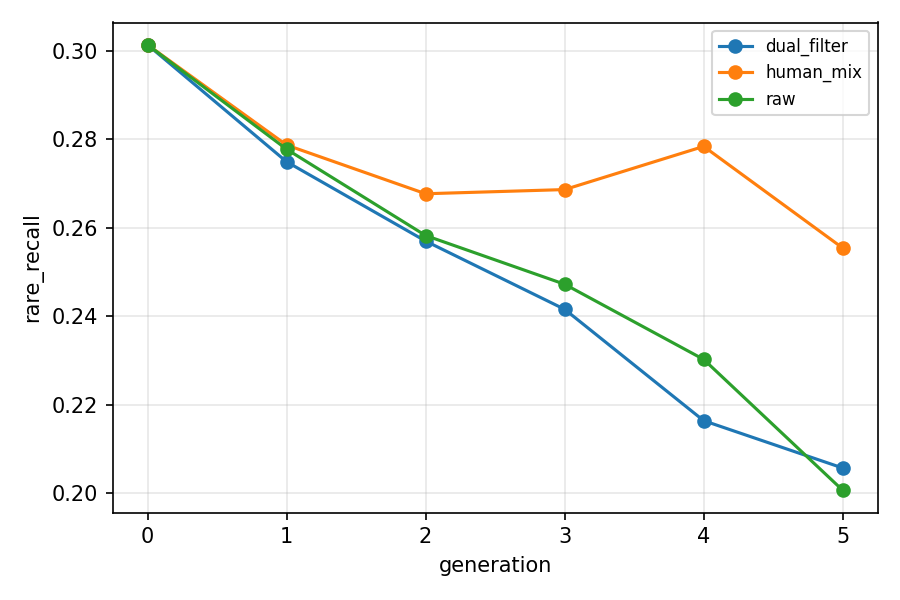

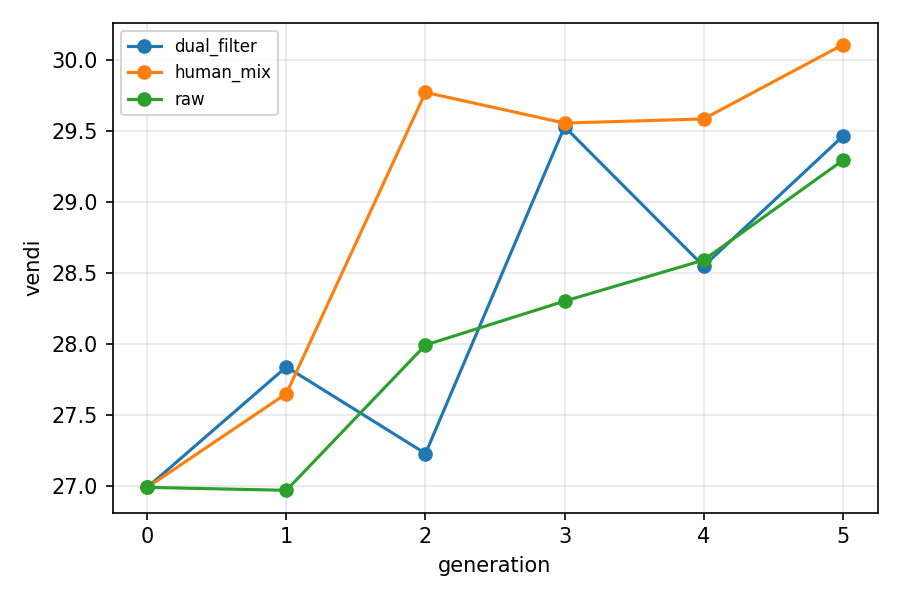

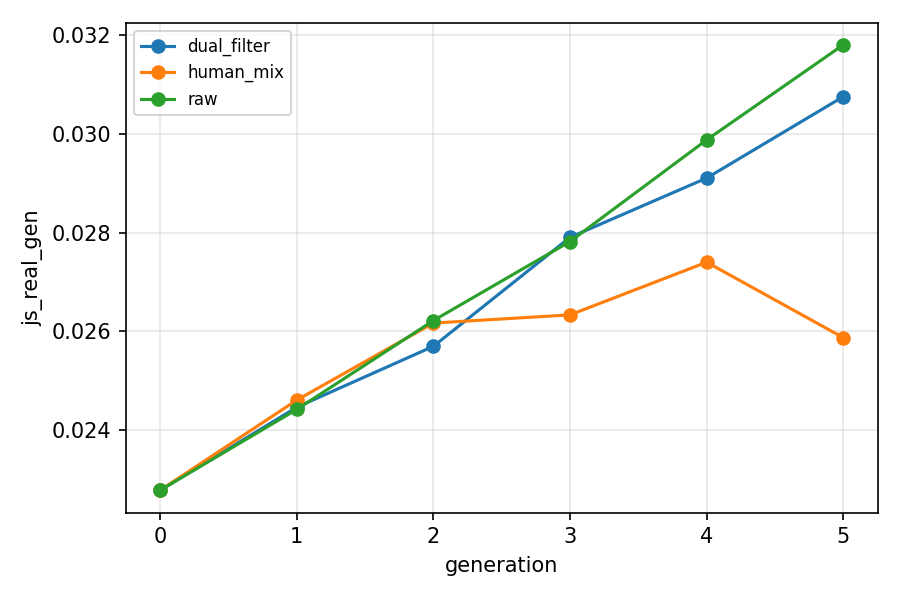

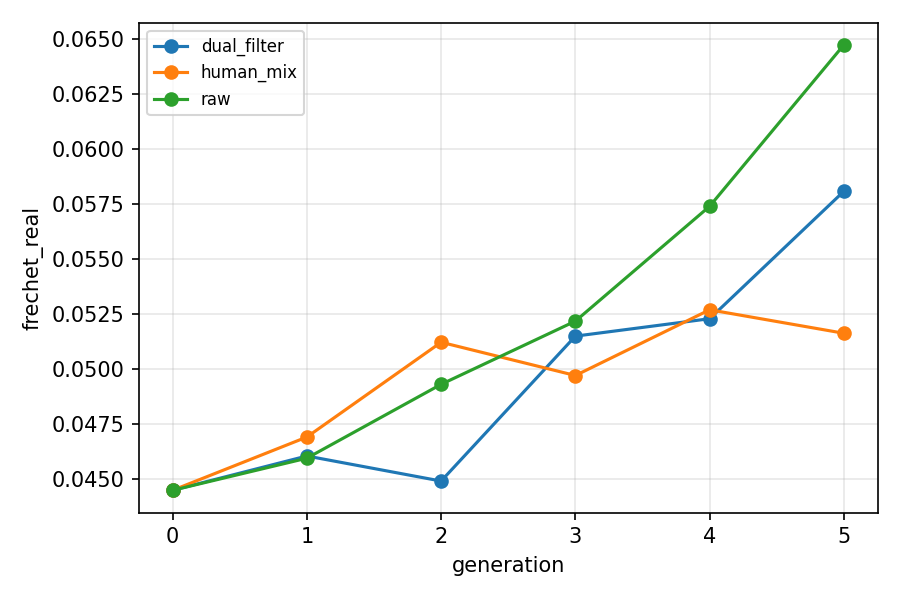

In [10]:
!python -m src.metrics.report --results {os.environ['MC_OUTPUT_DIR']} --out {DRIVE_ROOT}/results

import pandas as pd
from IPython.display import Image, display
summary = pd.read_csv(f"{DRIVE_ROOT}/results/summary.csv")
cols = ["test_ppl", "rare_recall", "vendi", "distinct_2", "js_real_gen", "frechet_real", "rep3_mean"]
display(summary[["line", "generation", "n_seeds", *[f"{c}_mean" for c in cols]]].round(4))
# Rising vendi/distinct alone is not "healthy diversity": read it together with js_real_gen and
# frechet_real (distance to real data) and rare_recall (tail preservation).
for metric in ["test_ppl", "rare_recall", "vendi", "js_real_gen", "frechet_real"]:
    display(Image(f"{DRIVE_ROOT}/results/plots/{metric}.png"))

## 8. Süre ve kaynak kontrolü
Her neslin süreleri `metrics.json` içindeki `time_*` alanlarındadır. İlk nesilden sonra buna bakıp
oturum başına kaç nesil sığacağını hesapla.

In [11]:
import json, glob
for path in sorted(glob.glob(f"{os.environ['MC_OUTPUT_DIR']}/**/metrics.json", recursive=True)):
    m = json.load(open(path))
    times = {k: v for k, v in m.items() if k.startswith("time_")}
    print(path.split("outputs/")[-1], m.get("gpu"), m.get("precision"), f"{sum(times.values())/60:.1f} dk", times)

_shared/seed0/gen0/metrics.json Tesla T4 float16 30.9 dk {'time_train': 363.93, 'time_test_ppl': 13.9, 'time_generate': 1425.67, 'time_eval': 49.8}
dual_filter/seed0/gen1/metrics.json Tesla T4 float16 29.4 dk {'time_features': 194.11, 'time_select': 1.89, 'time_train': 400.32, 'time_test_ppl': 14.48, 'time_generate': 1112.24, 'time_eval': 43.43}
dual_filter/seed0/gen2/metrics.json Tesla T4 float16 29.3 dk {'time_features': 161.36, 'time_select': 2.05, 'time_train': 416.01, 'time_test_ppl': 15.08, 'time_generate': 1120.45, 'time_eval': 40.11}
dual_filter/seed0/gen3/metrics.json Tesla T4 float16 29.1 dk {'time_features': 156.48, 'time_select': 1.97, 'time_train': 414.26, 'time_test_ppl': 14.56, 'time_generate': 1120.74, 'time_eval': 39.86}
dual_filter/seed0/gen4/metrics.json Tesla T4 float16 29.0 dk {'time_features': 149.84, 'time_select': 1.99, 'time_train': 416.91, 'time_test_ppl': 14.61, 'time_generate': 1117.32, 'time_eval': 36.72}
dual_filter/seed0/gen5/metrics.json Tesla T4 float16